# Cohort retention

**Question:** what share of each year's newcomers is still editing in the second month and in months 3–6?
Is it changing over the years?

**Data:** the `newcomers` and `edits` tables built by `pipeline/build_tables.py`: 133,976 newcomers whose first
human edit was in 2008–2025. Definitions are in [docs/metrics_definitions.md](../../docs/metrics_definitions.md):

- **Main metric:** at least one human edit in days 60–180 after the first edit (months 3–6).
- **Secondary metric:** at least one human edit in days 30–60 (the second month).
- **Cohort:** the calendar year of the first human edit.

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

DB_PATH = Path.cwd().parents[1] / "data" / "wiki.duckdb"
con = duckdb.connect(str(DB_PATH), read_only=True)


def query(sql):
    # convert_dtypes keeps whole numbers as integers instead of turning them into decimals
    return con.sql(sql).df().convert_dtypes()


# Chart style: two colors for two series, recessive grid and axes, text in neutral ink
BLUE, ORANGE = "#2a78d6", "#eb6834"
TEXT, TEXT_MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": TEXT_MUTED, "xtick.color": TEXT_MUTED, "ytick.color": TEXT_MUTED,
    "text.color": TEXT, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

## 1. Retention by cohort year

Each rate comes with a **95% confidence interval**: the range in which the true rate most likely lies, given that
each cohort is a limited number of people. It is wider when a cohort is smaller. Two years whose intervals don't
overlap differ by more than chance. The formula used is the usual one for a proportion:
rate ± 1.96 × √(rate × (1 − rate) / newcomers).

In [2]:
cohorts = query("""
    select
        cohort_year,
        count(*) as newcomers,
        sum(retained_months_3_to_6::int) as retained_main,
        sum(retained_second_month::int) as retained_second_month
    from newcomers
    group by cohort_year
    order by cohort_year
""").astype({"newcomers": int, "retained_main": int, "retained_second_month": int})

cohorts["main_pct"] = 100 * cohorts["retained_main"] / cohorts["newcomers"]
cohorts["second_month_pct"] = 100 * cohorts["retained_second_month"] / cohorts["newcomers"]

# 95% confidence interval for the main metric, in percentage points
p = cohorts["retained_main"] / cohorts["newcomers"]
cohorts["main_ci_pp"] = 100 * 1.96 * (p * (1 - p) / cohorts["newcomers"]) ** 0.5

cohorts.round(1)

,cohort_year,newcomers,retained_main,retained_second_month,main_pct,second_month_pct,main_ci_pp
0,2008,5534,793,456,14.3,8.2,0.9
1,2009,7579,658,380,8.7,5.0,0.6
2,2010,6755,551,362,8.2,5.4,0.7
3,2011,5831,434,307,7.4,5.3,0.7
4,2012,5856,474,369,8.1,6.3,0.7
5,2013,5251,321,253,6.1,4.8,0.6
6,2014,5130,277,189,5.4,3.7,0.6
7,2015,5634,278,209,4.9,3.7,0.6
8,2016,5768,283,199,4.9,3.5,0.6
9,2017,6844,330,241,4.8,3.5,0.5


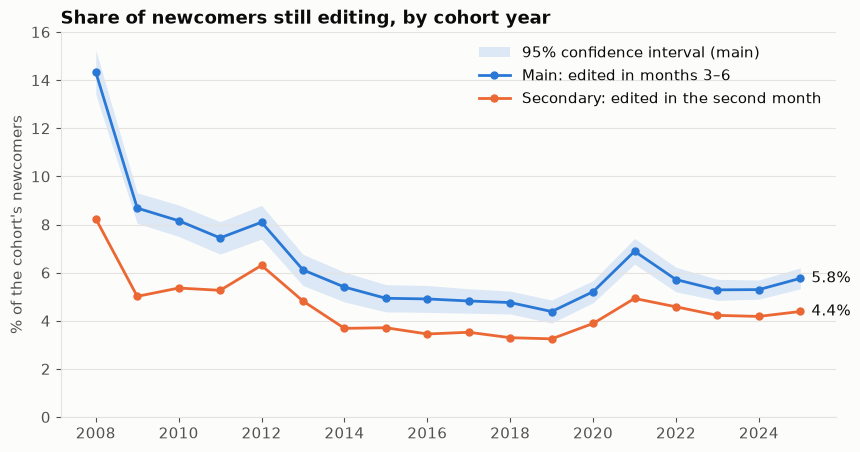

In [3]:
fig, ax = plt.subplots(figsize=(10, 5))
years = cohorts["cohort_year"]

ax.fill_between(years, cohorts["main_pct"] - cohorts["main_ci_pp"], cohorts["main_pct"] + cohorts["main_ci_pp"],
                color=BLUE, alpha=0.15, linewidth=0, label="95% confidence interval (main)")
ax.plot(years, cohorts["main_pct"], color=BLUE, linewidth=2, marker="o", markersize=5,
        label="Main: edited in months 3–6")
ax.plot(years, cohorts["second_month_pct"], color=ORANGE, linewidth=2, marker="o", markersize=5,
        label="Secondary: edited in the second month")

# Direct labels at the end of each line
last = cohorts.iloc[-1]
ax.annotate(f"{last['main_pct']:.1f}%", (last["cohort_year"], last["main_pct"]), xytext=(8, 0),
            textcoords="offset points", va="center", color=TEXT)
ax.annotate(f"{last['second_month_pct']:.1f}%", (last["cohort_year"], last["second_month_pct"]), xytext=(8, 0),
            textcoords="offset points", va="center", color=TEXT)

ax.set_title("Share of newcomers still editing, by cohort year")
ax.set_ylabel("% of the cohort's newcomers")
ax.set_xticks(range(2008, 2026, 2))
ax.set_ylim(0, 16)
ax.legend(frameon=False, loc="upper right")
plt.show()

## 2. How many newcomers stay, in people

A rate can fall while the number of people staying rises, if cohorts grow. The two charts below have separate
y-axes on purpose: they measure different things.

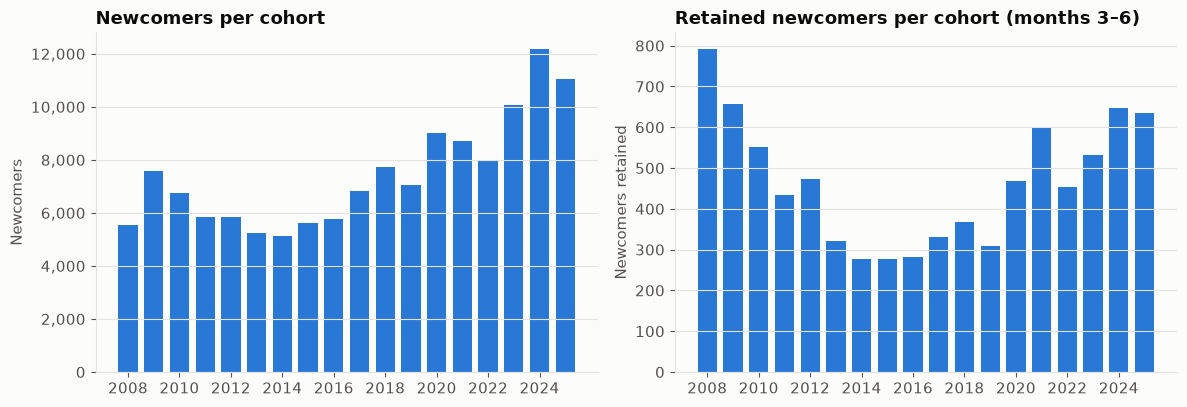

In [4]:
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.2))

left.bar(cohorts["cohort_year"], cohorts["newcomers"], color=BLUE, width=0.75)
left.set_title("Newcomers per cohort")
left.set_ylabel("Newcomers")

right.bar(cohorts["cohort_year"], cohorts["retained_main"], color=BLUE, width=0.75)
right.set_title("Retained newcomers per cohort (months 3–6)")
right.set_ylabel("Newcomers retained")

for ax in (left, right):
    ax.set_xticks(range(2008, 2026, 2))
    ax.yaxis.set_major_formatter(lambda value, _: f"{value:,.0f}")
plt.tight_layout()
plt.show()

## 3. When newcomers stop editing: the retention curve

The share of each cohort with at least one human edit in each 30-day month after the first edit, months 2–10
(month 1 is always 100%: it contains the first edit). Month 10 ends at day 300, the longest follow-up the
December 2025 newcomers allow.

In [5]:
curve = query("""
    with newcomer_edits as (
        select
            n.cohort_year,
            n.user_id,
            date_diff('second', n.first_edit_at, e.event_timestamp) / 86400.0 as days_since_first_edit
        from newcomers n
        join edits e on e.user_id = n.user_id and e.editor_type = 'registered'
    )
    select
        cohort_year,
        floor(days_since_first_edit / 30)::int + 1 as month_after_first_edit,
        count(distinct user_id) as newcomers_editing
    from newcomer_edits
    where days_since_first_edit < 300
    group by all
""")

curve = curve.merge(cohorts[["cohort_year", "newcomers"]], on="cohort_year")
curve["pct_editing"] = 100 * curve["newcomers_editing"].astype(int) / curve["newcomers"]
heatmap = curve[curve["month_after_first_edit"] >= 2].pivot(
    index="cohort_year", columns="month_after_first_edit", values="pct_editing")
heatmap.round(1)

month_after_first_edit,2,3,4,5,6,7,8,9,10
cohort_year,,,,,,,,,
2008,8.2,6.9,6.4,5.8,5.0,4.9,4.2,4.2,4.0
2009,5.0,4.0,3.5,3.0,2.7,2.7,2.5,2.4,1.9
2010,5.4,3.9,3.7,3.2,2.7,2.9,2.8,2.4,2.0
2011,5.3,3.6,3.1,2.6,2.3,2.3,1.8,1.8,1.9
2012,6.3,4.6,3.0,2.4,2.4,2.2,2.1,1.6,1.4
2013,4.8,3.4,2.3,1.9,2.0,1.5,1.7,1.6,1.7
2014,3.7,2.7,1.8,1.7,1.4,1.5,1.2,1.2,1.0
2015,3.7,2.4,1.8,1.5,1.6,1.4,1.3,1.4,1.2
2016,3.5,2.6,1.9,1.6,1.1,1.1,1.2,1.2,1.1


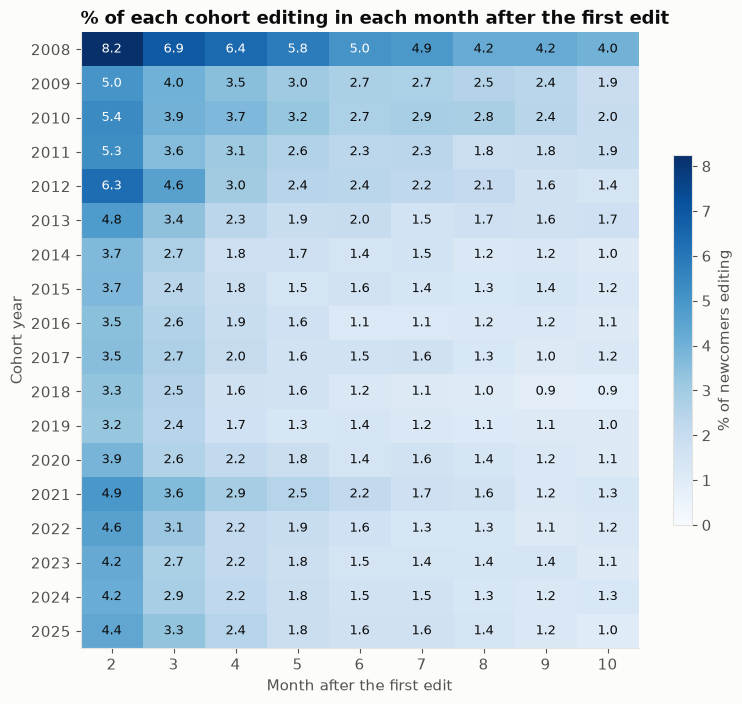

In [6]:
fig, ax = plt.subplots(figsize=(9, 8))
image = ax.imshow(heatmap.values, cmap="Blues", aspect="auto", vmin=0, vmax=heatmap.values.max())

# Write each value in its cell, in dark text on light cells and white text on dark ones
for row, year in enumerate(heatmap.index):
    for col, month in enumerate(heatmap.columns):
        value = heatmap.loc[year, month]
        ax.text(col, row, f"{value:.1f}", ha="center", va="center", fontsize=9,
                color="white" if value > 0.6 * heatmap.values.max() else TEXT)

ax.set_xticks(range(len(heatmap.columns)), labels=heatmap.columns)
ax.set_yticks(range(len(heatmap.index)), labels=heatmap.index)
ax.set_xlabel("Month after the first edit")
ax.set_ylabel("Cohort year")
ax.set_title("% of each cohort editing in each month after the first edit")
ax.grid(False)
fig.colorbar(image, ax=ax, label="% of newcomers editing", shrink=0.6)
plt.show()

## 4. Is the trend a change in who joins?

Newcomers whose account was created automatically (they had an account on another Wikimedia wiki) are retained
more often than those who signed up here. If the share of automatic accounts changed over the years, the overall
rate could move even if neither group changed. Two checks:

1. Retention for each creation method separately.
2. A **standardized rate**: what the overall rate would be if every cohort had the same mix of creation methods
   (the 2008–2025 average). If it follows the real rate, the mix doesn't explain the trend.

In [7]:
by_method = query("""
    select
        cohort_year,
        -- peer (another user) and unknown are small groups, so they are combined
        case when created_by in ('self', 'system') then created_by else 'other' end as created_by,
        count(*) as newcomers,
        avg(retained_months_3_to_6::int) as retention_rate
    from newcomers
    group by all
""")
by_method["share_of_cohort"] = by_method["newcomers"] / by_method.groupby("cohort_year")["newcomers"].transform("sum")

# Standardized rate: each method's rate in that year, weighted by the method's share of all 2008-2025 newcomers
overall_mix = by_method.groupby("created_by")["newcomers"].sum() / by_method["newcomers"].sum()
by_method["weight"] = by_method["created_by"].map(overall_mix)
standardized = (by_method["retention_rate"] * by_method["weight"]).groupby(by_method["cohort_year"]).sum()

method_table = by_method.pivot(index="cohort_year", columns="created_by", values="retention_rate") * 100
method_table["share_system_pct"] = by_method[by_method["created_by"] == "system"].set_index("cohort_year")["share_of_cohort"] * 100
method_table["actual_pct"] = cohorts.set_index("cohort_year")["main_pct"]
method_table["standardized_pct"] = standardized * 100
print("Average mix 2008-2025:", (overall_mix * 100).round(1).to_dict())
method_table.round(1)

Average mix 2008-2025: {'other': 3.1, 'self': 35.2, 'system': 61.7}


created_by,other,self,system,share_system_pct,actual_pct,standardized_pct
cohort_year,,,,,,
2008,15.5,9.2,20.3,43.8,14.3,16.3
2009,7.7,4.1,11.6,57.8,8.7,8.8
2010,7.5,2.2,11.1,61.8,8.2,7.8
2011,7.9,3.0,9.7,49.8,7.4,7.3
2012,8.7,5.2,9.5,57.9,8.1,7.9
2013,6.2,3.4,7.4,63.0,6.1,6.0
2014,21.1,2.0,6.9,63.2,5.4,5.6
2015,2.9,1.7,6.7,63.9,4.9,4.8
2016,17.9,2.0,6.5,62.9,4.9,5.3


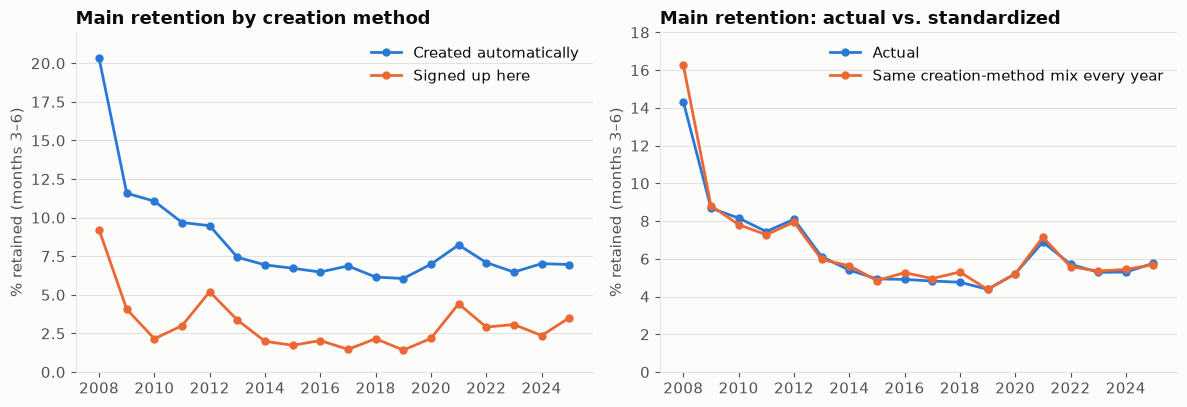

In [8]:
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.2))

left.plot(method_table.index, method_table["system"], color=BLUE, linewidth=2, marker="o", markersize=5,
          label="Created automatically")
left.plot(method_table.index, method_table["self"], color=ORANGE, linewidth=2, marker="o", markersize=5,
          label="Signed up here")
left.set_title("Main retention by creation method")
left.set_ylabel("% retained (months 3–6)")
left.set_ylim(0, 22)
left.legend(frameon=False)

right.plot(method_table.index, method_table["actual_pct"], color=BLUE, linewidth=2, marker="o", markersize=5,
           label="Actual")
right.plot(method_table.index, method_table["standardized_pct"], color=ORANGE, linewidth=2, marker="o",
           markersize=5, label="Same creation-method mix every year")
right.set_title("Main retention: actual vs. standardized")
right.set_ylabel("% retained (months 3–6)")
right.set_ylim(0, 18)
right.legend(frameon=False, loc="upper right")

for ax in (left, right):
    ax.set_xticks(range(2008, 2026, 2))
plt.tight_layout()
plt.show()

## 5. Where the first edit was made

Main retention for all 2008–2025 newcomers, by the part of the wiki where they made their first edit.

In [9]:
by_first_namespace = query("""
    select
        case first_edit_namespace
            when 0 then 'Article'
            when 2 then 'Own profile page'
            when 3 then 'User talk page'
            else 'Other' end as first_edit_in,
        count(*) as newcomers,
        sum(retained_months_3_to_6::int) as retained
    from newcomers
    group by first_edit_in
    order by newcomers desc
""").astype({"newcomers": int, "retained": int})

p = by_first_namespace["retained"] / by_first_namespace["newcomers"]
by_first_namespace["retained_pct"] = 100 * p
by_first_namespace["ci_pp"] = 100 * 1.96 * (p * (1 - p) / by_first_namespace["newcomers"]) ** 0.5
by_first_namespace.round(1)

,first_edit_in,newcomers,retained,retained_pct,ci_pp
0,Article,100560,5834,5.8,0.1
1,Own profile page,16283,1337,8.2,0.4
2,Other,11741,1048,8.9,0.5
3,User talk page,5392,196,3.6,0.5


## Findings

**1. Retention fell steeply from 2008 to 2015, then stayed low until 2019.** The main metric went from 14.3% (2008)
to 4.9% (2015) and 4.4% (2019), less than a third of its 2008 level. The second-month metric fell from 8.2% to 3.2%.

**2. It rose in 2021 and has stayed above the 2015–2019 level since.** The main metric reached 6.9% in 2021 and was
5.3–5.8% in 2022–2025. The difference from 2019 is larger than chance: the 95% intervals don't overlap
(2019: 3.9–4.9%, 2021: 6.4–7.4%, 2025: 5.3–6.2%).

**3. In people, the number of retained newcomers is back near its 2009 level.** It fell from 793 (2008) to about 280
a year in 2014–2016 and rose to 646 (2024) and 636 (2025). The rise comes from larger cohorts, which more than
doubled from 5,130 (2014) to 12,201 (2024), while the rate stayed about the same (5.4% in 2014, 5.3% in 2024).

**4. Most newcomers leave right after their first month, and the recent improvement is in the early months.**
Only 3.2–8.2% of a cohort edits in month 2; after that the share fades slowly, to 0.9–4.0% in month 10.
The 2021–2025 cohorts are higher than the 2014–2019 cohorts in the early months (month 2: 4.2–4.9% vs. 3.2–3.7%),
but by month 10 both groups are at 0.9–1.3%.

**5. The trend isn't explained by who joins.** Newcomers with an automatically created account are retained about two to five
times as often as those who signed up here (1.8 to 5.1 times, depending on the year), and their share of each cohort has been 62–67% since 2013. Both groups
show the same decline and the same 2021 rise. With the same creation-method mix every year, the rate differs from the
actual rate by at most 0.6 percentage points from 2009 on.

**6. Newcomers who start on their own profile page are retained more often than those who start in an article**
(8.2% vs. 5.8%), and those who start on a user talk page least often (3.6%). These figures pool all cohorts, and
non-article first edits were more common in the years with higher retention, so part of this difference comes from the year.